In [1]:
import pandas as pd
from pathlib import Path

In [2]:
def probe(x):
    display(x)
    return x

def noprobe(x):
    return x

In [3]:
def project_root(root = Path.cwd(), indicator="pyproject.toml"):
    if indicator in noprobe({x.name for x in root.iterdir()}):
        return root
    else:
        return project_root(root = root.parent, indicator=indicator)

project_root()

PosixPath('/home/fufu/myllm')

In [4]:
dataset_root = project_root() / "repo" / "dataset" / "ebible" / "corpus"
df = pd.DataFrame(dataset_root.iterdir())
df.columns = ["path"]
df["name"] = df.path.apply(lambda x: x.name)


In [23]:
test = df.iloc[0,0]
test

PosixPath('/home/fufu/myllm/repo/dataset/ebible/corpus/apr-apr.txt')

In [26]:
stat = test.stat()

In [5]:
df["content_line_count"] = df.path.apply(lambda x: len(x.read_text().strip().split("\n")))
df

,path,name,content_line_count
0,/home/fufu/myllm/repo/dataset/ebible/corpus/ap...,apr-apr.txt,7957
1,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cme-cmeNT.txt,7957
2,/home/fufu/myllm/repo/dataset/ebible/corpus/be...,bef-bef.txt,7957
3,/home/fufu/myllm/repo/dataset/ebible/corpus/en...,eng-engfbv.txt,31170
4,/home/fufu/myllm/repo/dataset/ebible/corpus/cp...,cpa-cpaNT.txt,7957
...,...,...,...
1074,/home/fufu/myllm/repo/dataset/ebible/corpus/kp...,kpr-kpr.txt,17227
1075,/home/fufu/myllm/repo/dataset/ebible/corpus/sa...,san-sankhm.txt,7957
1076,/home/fufu/myllm/repo/dataset/ebible/corpus/am...,amp-amp.txt,7957
1077,/home/fufu/myllm/repo/dataset/ebible/corpus/wa...,waj-waj.txt,7957


In [6]:
df["lang subversion".split()] = df.name.str.extract("([a-zA-Z0-9]+)\\-([a-zA-Z0-9]+)", expand=True)
df

,path,name,content_line_count,lang,subversion
0,/home/fufu/myllm/repo/dataset/ebible/corpus/ap...,apr-apr.txt,7957,apr,apr
1,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cme-cmeNT.txt,7957,cme,cmeNT
2,/home/fufu/myllm/repo/dataset/ebible/corpus/be...,bef-bef.txt,7957,bef,bef
3,/home/fufu/myllm/repo/dataset/ebible/corpus/en...,eng-engfbv.txt,31170,eng,engfbv
4,/home/fufu/myllm/repo/dataset/ebible/corpus/cp...,cpa-cpaNT.txt,7957,cpa,cpaNT
...,...,...,...,...,...
1074,/home/fufu/myllm/repo/dataset/ebible/corpus/kp...,kpr-kpr.txt,17227,kpr,kpr
1075,/home/fufu/myllm/repo/dataset/ebible/corpus/sa...,san-sankhm.txt,7957,san,sankhm
1076,/home/fufu/myllm/repo/dataset/ebible/corpus/am...,amp-amp.txt,7957,amp,amp
1077,/home/fufu/myllm/repo/dataset/ebible/corpus/wa...,waj-waj.txt,7957,waj,waj


<Axes: ylabel='Frequency'>

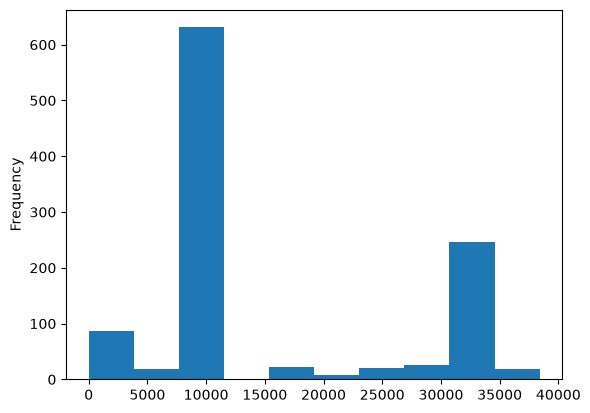

In [44]:
df.content_line_count.plot.hist()

In [49]:
df.content_line_count.value_counts().sort_index().to_dict()

{1: 44,
 4: 1,
 7: 2,
 48: 1,
 621: 1,
 678: 9,
 879: 1,
 1071: 4,
 1151: 11,
 1749: 1,
 1829: 1,
 2719: 4,
 3036: 1,
 3513: 1,
 3714: 1,
 3760: 1,
 3779: 3,
 4785: 1,
 5218: 1,
 5479: 1,
 5853: 1,
 6157: 1,
 6208: 1,
 6215: 1,
 6456: 2,
 6550: 1,
 6886: 2,
 7228: 1,
 7499: 1,
 7527: 2,
 7552: 2,
 7936: 1,
 7957: 629,
 8570: 1,
 14055: 1,
 15519: 1,
 16674: 1,
 17227: 19,
 18297: 1,
 18984: 1,
 20869: 3,
 22648: 2,
 22901: 1,
 22947: 1,
 23207: 3,
 23213: 2,
 23636: 2,
 24041: 13,
 26992: 2,
 27138: 1,
 27998: 8,
 29357: 1,
 29637: 1,
 29876: 2,
 29959: 1,
 30441: 7,
 30617: 1,
 30653: 1,
 30712: 1,
 30765: 3,
 30871: 2,
 31154: 2,
 31170: 240,
 35726: 8,
 37828: 2,
 37829: 4,
 37836: 4,
 38404: 1}

In [ ]:
df.content_line_count.plot.hist()

In [38]:
text = test.read_text()
len(text.strip().split("\n"))

7957

In [61]:
df.query("content_line_count == 31170")

,path,name,content_line_count,lang,subversion
3,/home/fufu/myllm/repo/dataset/ebible/corpus/en...,eng-engfbv.txt,31170,eng,engfbv
17,/home/fufu/myllm/repo/dataset/ebible/corpus/gv...,gvs-gvs.txt,31170,gvs,gvs
19,/home/fufu/myllm/repo/dataset/ebible/corpus/ms...,msy-msy2020.txt,31170,msy,msy2020
20,/home/fufu/myllm/repo/dataset/ebible/corpus/na...,nas-nas.txt,31170,nas,nas
25,/home/fufu/myllm/repo/dataset/ebible/corpus/by...,byr-byr.txt,31170,byr,byr
...,...,...,...,...,...
1042,/home/fufu/myllm/repo/dataset/ebible/corpus/en...,eng-engBBE.txt,31170,eng,engBBE
1054,/home/fufu/myllm/repo/dataset/ebible/corpus/gn...,gnn-gnn.txt,31170,gnn,gnn
1056,/home/fufu/myllm/repo/dataset/ebible/corpus/en...,eng-engwebp.txt,31170,eng,engwebp
1057,/home/fufu/myllm/repo/dataset/ebible/corpus/cb...,cbr-cbrNT.txt,31170,cbr,cbrNT


In [54]:
df.query("name.str.contains('zh')")

,path,name,content_line_count
685,/home/fufu/myllm/repo/dataset/ebible/corpus/bz...,bzh-bzh.txt,7957


In [63]:
df.value_counts("lang")

lang
eng    47
san    20
grc     8
cak     7
rmy     6
       ..
top     1
kpr     1
amp     1
waj     1
mkl     1
Name: count, Length: 883, dtype: int64

In [64]:
df.query("content_line_count == 31170").value_counts("lang")

lang
eng    13
deu     5
spa     4
urd     4
uig     4
       ..
som     1
pma     1
acu     1
gnn     1
cbr     1
Name: count, Length: 196, dtype: int64

In [71]:
df.query("name.str.contains('ch')")

,path,name,content_line_count,lang,subversion
32,/home/fufu/myllm/repo/dataset/ebible/corpus/tc...,tcz-tczchongthu.txt,31170,tcz,tczchongthu
61,/home/fufu/myllm/repo/dataset/ebible/corpus/ch...,chz-chzNTps.txt,7957,chz,chzNTps
150,/home/fufu/myllm/repo/dataset/ebible/corpus/ch...,cha-cha.txt,14055,cha,cha
195,/home/fufu/myllm/repo/dataset/ebible/corpus/ch...,chf-chfNT.txt,7957,chf,chfNT
337,/home/fufu/myllm/repo/dataset/ebible/corpus/ch...,chd-chdNT.txt,7957,chd,chdNT
499,/home/fufu/myllm/repo/dataset/ebible/corpus/ch...,chk-chk.txt,31170,chk,chk
556,/home/fufu/myllm/repo/dataset/ebible/corpus/nc...,nch-nchBl.txt,31170,nch,nchBl
664,/home/fufu/myllm/repo/dataset/ebible/corpus/ch...,chq-chqNT.txt,7957,chq,chqNT
674,/home/fufu/myllm/repo/dataset/ebible/corpus/sc...,sch-sch.txt,7957,sch,sch
814,/home/fufu/myllm/repo/dataset/ebible/corpus/bc...,bch-bch.txt,31170,bch,bch


In [72]:
df["content_top_10"] = df.path.apply(lambda x: x.read_text().strip().split("\n")[:10])
df

,path,name,content_line_count,lang,subversion,content_top_10
0,/home/fufu/myllm/repo/dataset/ebible/corpus/ap...,apr-apr.txt,7957,apr,apr,"[Nga bet tapiti rara ke Yesu Kirisi nga, ngan ..."
1,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cme-cmeNT.txt,7957,cme,cmeNT,[Yesu-Kirsa bĩncuɔmbaŋ cuu ba-naa dumaa ku ya...
2,/home/fufu/myllm/repo/dataset/ebible/corpus/be...,bef-bef.txt,7957,bef,bef,[Ma fayahi Yesu Kilisitohi tataꞌagi enigiꞌani ...
3,/home/fufu/myllm/repo/dataset/ebible/corpus/en...,eng-engfbv.txt,31170,eng,engfbv,[In the beginning God created the heavens and ...
4,/home/fufu/myllm/repo/dataset/ebible/corpus/cp...,cpa-cpaNT.txt,7957,cpa,cpaNT,[Lah¹la² báh³ lǿa¹² si² ja³ni³ton¹² dsa² hóg¹ ...
...,...,...,...,...,...,...
1074,/home/fufu/myllm/repo/dataset/ebible/corpus/kp...,kpr-kpr.txt,17227,kpr,kpr,[Genembo mave ari ekoko embo da dengoro indari...
1075,/home/fufu/myllm/repo/dataset/ebible/corpus/sa...,san-sankhm.txt,7957,san,sankhm,[ឥព្រាហីមះ សន្តានោ ទាយូទ៑ តស្យ សន្តានោ យីឝុខ្រ...
1076,/home/fufu/myllm/repo/dataset/ebible/corpus/am...,amp-amp.txt,7957,amp,amp,[Ndarm Jisas Kraisrhu nkifraroh yufayem. Jisas...
1077,/home/fufu/myllm/repo/dataset/ebible/corpus/wa...,waj-waj.txt,7957,waj,waj,[Aanna Yisuu Kirisiinna oyaiya kuavai. Aaparah...


In [76]:
df_sentences = df.explode("content_top_10")

In [80]:
from collections import Counter
def space_counts(s):
    return Counter(s)[' ']


df_sentences["space_counts"] = df_sentences.content_top_10.apply(space_counts)
df_sentences

,path,name,content_line_count,lang,subversion,content_top_10,space_counts
0,/home/fufu/myllm/repo/dataset/ebible/corpus/ap...,apr-apr.txt,7957,apr,apr,"Nga bet tapiti rara ke Yesu Kirisi nga, ngan Y...",20
0,/home/fufu/myllm/repo/dataset/ebible/corpus/ap...,apr-apr.txt,7957,apr,apr,Ngan rara tani in bet tapiti le ipa ye Awaram ...,37
0,/home/fufu/myllm/repo/dataset/ebible/corpus/ap...,apr-apr.txt,7957,apr,apr,Inbe Yuda tani in Peres iye Sarra yo tinadi Ta...,22
0,/home/fufu/myllm/repo/dataset/ebible/corpus/ap...,apr-apr.txt,7957,apr,apr,Inbe Ram in Aminadap tamana. Inbe Aminadap in ...,14
0,/home/fufu/myllm/repo/dataset/ebible/corpus/ap...,apr-apr.txt,7957,apr,apr,"Inbe Salmon tani, in Boas yo tinana Reap i, in...",25
...,...,...,...,...,...,...,...
1078,/home/fufu/myllm/repo/dataset/ebible/corpus/mk...,mkl-mkl.txt,7957,mkl,mkl,Izɑi mɔ í bí Dɑvidi iyi í nɑ í jɛ ilɑɑluu. Dɑv...,25
1078,/home/fufu/myllm/repo/dataset/ebible/corpus/mk...,mkl-mkl.txt,7957,mkl,mkl,Sɑlomɔɔ mɔ í bí Roboɑmu. Roboɑmu mɔ í bí Abiɑ....,14
1078,/home/fufu/myllm/repo/dataset/ebible/corpus/mk...,mkl-mkl.txt,7957,mkl,mkl,Azɑfu mɔ í bí Zozɑfɑti. Zozɑfɑti mɔ í bí Zorɑm...,14
1078,/home/fufu/myllm/repo/dataset/ebible/corpus/mk...,mkl-mkl.txt,7957,mkl,mkl,Oziɑsi mɔ í bí Zoɑtɑmu. Zoɑtɑmu mɔ í bí Akɑzi....,14


In [85]:
df_sentences.space_counts.value_counts().sort_index()

space_counts
0      327
1       11
2       30
3        7
4       29
      ... 
214      1
305      1
359      1
367      1
565      1
Name: count, Length: 104, dtype: int64

In [87]:
df_sentences.query("space_counts == 0").value_counts("content_top_10")

content_top_10
<range>                                                            256
                                                                    49
ཐོག་མར་དཀོན་མཆོག་གིས་ནམ་མཁའ་དང་ས་གཞི་གསར་དུ་བཀོད་པ་ལགས༌སོ།།          1
ཁོང་གིས་འོད་ནི་ལེགས་པར་དགོངས་ཏེ་འོད་དང་མུན་པའི་དབྱེ་བ༌ཕྱེས་སོ།།      1
本书为亚伯拉罕和大卫的后代弥赛亚的记录。首先在此回述其家谱：                                       1
亚伯拉罕为以撒之父；以撒为雅各之父；雅各为犹大及其兄弟之父；                                       1
犹大（妻为塔玛）为法勒斯和谢拉之父；法勒斯为希斯仑之父；希斯仑为亚兰之父；                                1
亚兰为亚米拿达之父；亚米拿达为拿顺之父，拿顺为撒门之父；                                         1
撒门（妻为拉哈德）为博奥兹之父；博奥兹（妻为露丝）为俄备得之父；俄备得为耶西之父；                            1
耶西为大卫王之父；大卫（娶乌利亚之妻）为所罗门之父；                                           1
所罗门为罗波安之父；罗波安为亚比雅之父；亚比雅为亚撒之父；                                        1
亚撒为约沙法之父；约沙法为约兰之父；约兰为乌西亚之父；                                          1
乌西亚为约坦之父；约坦为亚哈斯之父；亚哈斯为希西加之父；                                         1
希西加为玛拿西之父；玛拿西为亚门之父；亚门为约西亚之父；                                  

In [88]:
df_sentences.query("content_top_10.str.contains('本书为亚伯拉罕和大卫的后代弥赛亚的记录。首先在此回述其家谱')")

,path,name,content_line_count,lang,subversion,content_top_10,space_counts
903,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cmn-cmnfeb.txt,7957,cmn,cmnfeb,本书为亚伯拉罕和大卫的后代弥赛亚的记录。首先在此回述其家谱：,0


In [111]:
df_sentences.query("space_counts == 15").value_counts("content_top_10")

content_top_10
who married Moabite women named Orpah and Ruth. After they had lived there about ten years,                              2
Abiramu siire da *Isaki. Isaki sire da *Yakɔbu. Yakɔbu sire da *Yuda a naara bisãlmba namba.                            1
God called the expanse, “sky.” So there was evening, and then the morning, making day two.                               1
Juda-ni Péres kene Sera kene mirim, yi kanuselenga anum Tema; Péres-ni Esron mirim; Esron-ni Ram mirim;                  1
Ulu nulo ludongo lwo lukolo lwa Zumbe Yesu Kilisito, mwelekwa ywa Daudi andaga mlukolo ywa Ibulahimu.                    1
                                                                                                                        ..
Abraham ixti̱cú huá Isaac, Isaac ixti̱cú huá Jacob, y Jacob ixti̱cú huá Judá (ixca̱kalhí ma̱s ixnata̱camán).             1
Endada oro oro redae God dodo janje ekoko eraeri? Ne redae manaka beká irae ava gayeraeri?                               1
B

In [121]:
df_sentences.query("content_top_10.str.contains('Genesis')")

,path,name,content_line_count,lang,subversion,content_top_10,space_counts


In [116]:
df_sentences.query("lang == 'cmn'").explode("content_top_10")

,path,name,content_line_count,lang,subversion,content_top_10,space_counts
207,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cmn-cmn_cu89s.txt,1,cmn,cmn,,0
426,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cmn-cmn_cu89t.txt,1,cmn,cmn,,0
903,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cmn-cmnfeb.txt,7957,cmn,cmnfeb,本书为亚伯拉罕和大卫的后代弥赛亚的记录。首先在此回述其家谱：,0
903,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cmn-cmnfeb.txt,7957,cmn,cmnfeb,亚伯拉罕为以撒之父；以撒为雅各之父；雅各为犹大及其兄弟之父；,0
903,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cmn-cmnfeb.txt,7957,cmn,cmnfeb,犹大（妻为塔玛）为法勒斯和谢拉之父；法勒斯为希斯仑之父；希斯仑为亚兰之父；,0
903,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cmn-cmnfeb.txt,7957,cmn,cmnfeb,亚兰为亚米拿达之父；亚米拿达为拿顺之父，拿顺为撒门之父；,0
903,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cmn-cmnfeb.txt,7957,cmn,cmnfeb,撒门（妻为拉哈德）为博奥兹之父；博奥兹（妻为露丝）为俄备得之父；俄备得为耶西之父；,0
903,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cmn-cmnfeb.txt,7957,cmn,cmnfeb,耶西为大卫王之父；大卫（娶乌利亚之妻）为所罗门之父；,0
903,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cmn-cmnfeb.txt,7957,cmn,cmnfeb,所罗门为罗波安之父；罗波安为亚比雅之父；亚比雅为亚撒之父；,0
903,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cmn-cmnfeb.txt,7957,cmn,cmnfeb,亚撒为约沙法之父；约沙法为约兰之父；约兰为乌西亚之父；,0


In [123]:
"\n".split("\n")

['', '']

In [7]:
df_standard = df.query("content_line_count == 7957").copy()
#df_standard.to_csv("standard_content.csv")

In [8]:
df_standard["sentence"] = df_standard.path.apply(lambda x: x.read_text().strip().split("\n"))
df_standard.explode("sentence").to_csv("bible_sentences.csv")

In [127]:
del df_standard["content_top_10"]

In [128]:
df_standard

,path,name,content_line_count,lang,subversion,sentence
0,/home/fufu/myllm/repo/dataset/ebible/corpus/ap...,apr-apr.txt,7957,apr,apr,"[Nga bet tapiti rara ke Yesu Kirisi nga, ngan ..."
1,/home/fufu/myllm/repo/dataset/ebible/corpus/cm...,cme-cmeNT.txt,7957,cme,cmeNT,[Yesu-Kirsa bĩncuɔmbaŋ cuu ba-naa dumaa ku ya...
2,/home/fufu/myllm/repo/dataset/ebible/corpus/be...,bef-bef.txt,7957,bef,bef,[Ma fayahi Yesu Kilisitohi tataꞌagi enigiꞌani ...
4,/home/fufu/myllm/repo/dataset/ebible/corpus/cp...,cpa-cpaNT.txt,7957,cpa,cpaNT,[Lah¹la² báh³ lǿa¹² si² ja³ni³ton¹² dsa² hóg¹ ...
5,/home/fufu/myllm/repo/dataset/ebible/corpus/sa...,san-sanvel.txt,7957,san,sanvel,[ibraahiima.h santaano daayuud tasya santaano ...
...,...,...,...,...,...,...
1073,/home/fufu/myllm/repo/dataset/ebible/corpus/to...,top-topNT.txt,7957,top,topNT,[Ixli̱talakapasnicán Jesús maká̱n ca̱ma̱lacatz...
1075,/home/fufu/myllm/repo/dataset/ebible/corpus/sa...,san-sankhm.txt,7957,san,sankhm,[ឥព្រាហីមះ សន្តានោ ទាយូទ៑ តស្យ សន្តានោ យីឝុខ្រ...
1076,/home/fufu/myllm/repo/dataset/ebible/corpus/am...,amp-amp.txt,7957,amp,amp,[Ndarm Jisas Kraisrhu nkifraroh yufayem. Jisas...
1077,/home/fufu/myllm/repo/dataset/ebible/corpus/wa...,waj-waj.txt,7957,waj,waj,[Aanna Yisuu Kirisiinna oyaiya kuavai. Aaparah...


In [ ]:
!ls -l